#Iris Classification



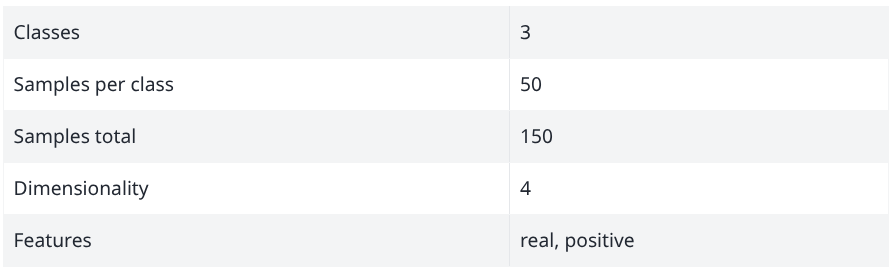

In [2]:
import sklearn.datasets as skdata
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = skdata.load_iris(as_frame=True)
df

{'data':      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
 0                  5.1               3.5                1.4               0.2
 1                  4.9               3.0                1.4               0.2
 2                  4.7               3.2                1.3               0.2
 3                  4.6               3.1                1.5               0.2
 4                  5.0               3.6                1.4               0.2
 ..                 ...               ...                ...               ...
 145                6.7               3.0                5.2               2.3
 146                6.3               2.5                5.0               1.9
 147                6.5               3.0                5.2               2.0
 148                6.2               3.4                5.4               2.3
 149                5.9               3.0                5.1               1.8
 
 [150 rows x 4 columns],
 'target': 0     

In [4]:
dados = df.data
label = df.target

print("tipos de iris:", df.target_names)

tipos de iris: ['setosa' 'versicolor' 'virginica']


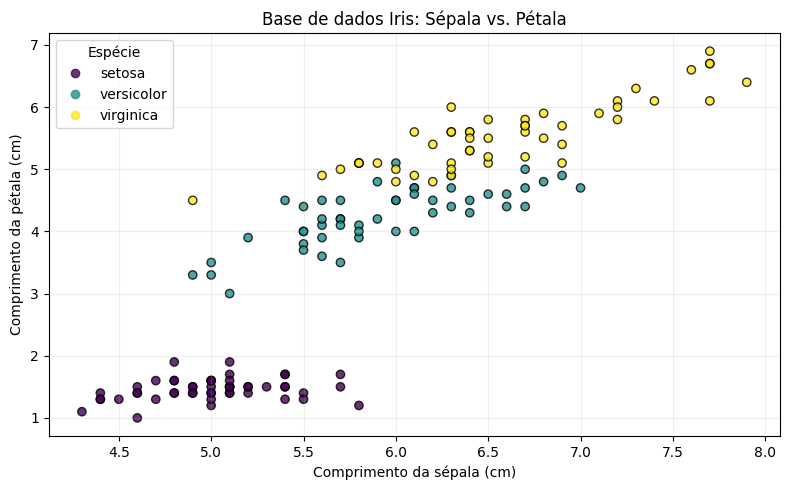

In [5]:
#vamos plotar um gráfico das propriedades para visualizar os pontos

# Selecionar duas propriedades da base completa
x_axis = df.frame["sepal length (cm)"]
y_axis = df.frame["petal length (cm)"]

# Criar o gráfico
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    x_axis,
    y_axis,
    c=df.frame["target"],
    cmap="viridis",
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Comprimento da sépala (cm)")
plt.ylabel("Comprimento da pétala (cm)")
plt.title("Base de dados Iris: Sépala vs. Pétala")

# Legenda para as espécies
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(df.target_names),
    title="Espécie"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [6]:
x_train, x_test, y_train, y_test = train_test_split(dados, label, test_size=0.3, random_state=25)

In [7]:
import numpy as np

def distance(x, y): #distancia euclidiana
    return np.sqrt(sum((x - y)**2))

class KNearestNeighbors:
    # inicia a variavel que guarda a quantidade de vizinhos proximos
    def __init__(self, k):
        self.k = k

    # disposição dos pontos no espaço
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X_val):
      y_pred = []

      X_val_arr = X_val.to_numpy()
      X_train_arr = self.X_train.to_numpy()
      y_train_arr = self.y_train.to_numpy()

      for row_val in X_val_arr:
          distances = []

          for index_train, row_train in enumerate(X_train_arr):
              distances.append([
                  index_train,
                  distance(row_val, row_train)
              ])

          distances = sorted(distances, key=lambda x: x[1])

          # Selecionar os k vizinhos mais próximos
          nearestNeighbors = distances[:self.k]

          # Obter as classes dos vizinhos
          result = []
          for neighbor in nearestNeighbors:
              result.append(y_train_arr[int(neighbor[0])])

          # Escolher a classe mais frequente
          classes, counts = np.unique(result, return_counts=True)
          y_pred.append(classes[np.argmax(counts)])

      return y_pred

    def accuracy(self, y_val, y_pred):
        total = 0
        for val, pred in zip(y_val, y_pred):
            if (val == pred):
                total += 1
        return total / len(y_val)

In [8]:
# definimos então um modelo
model = KNearestNeighbors(k=5)
# realizamos o treinamento
model.fit(x_train, y_train)
#predição
y_pred = model.predict(x_test)
# e finalmente teste da precisão
model.accuracy(y_pred, y_test)

0.9555555555555556

In [9]:
#podemos também ver o comportamento do modelo para difentes valores de K
ks = [3, 5, 7, 9]
predicoes = {}

for k in ks:
    model = KNearestNeighbors(k=k)
    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)
    predicoes[k] = y_pred

    print(f"k={k}, acurácia={model.accuracy(y_test, y_pred)}")

k=3, acurácia=0.9555555555555556
k=5, acurácia=0.9555555555555556
k=7, acurácia=0.9333333333333333
k=9, acurácia=0.9555555555555556


In [10]:
#vamos testar em uma iris com valores aleatorios:
x_aleatorio = pd.DataFrame({'sepal length (cm)': 4.9, 'sepal width (cm)': 3, 'petal length (cm)': 1.2,
       'petal width (cm)': 0.3}, index=[0])


#predição
y_pred = model.predict(x_aleatorio)
print(df.target_names[y_pred])


['setosa']
